# 01_EDA_Preprocessing – Khám phá dữ liệu & Chiến lược tiền xử lý

**Đề tài:** Dự đoán giá nhà Ames Housing (hồi quy) · **Người phụ trách:** Lưu Ngọc Tuấn Anh

**Nguyên tắc chống rò rỉ dữ liệu:** mọi thống kê trong notebook này chỉ tính trên **tập train**.
Notebook chỉ *phân tích và đề xuất*; các bước học từ dữ liệu (impute, scale, encode) được thực hiện
**trong Pipeline** ở notebook 02, không fit trực tiếp ở đây.

| Mục | Nội dung |
|---|---|
| 1 | Đọc dữ liệu, chia train/test, kiểm tra cách đọc chuỗi `"None"` |
| 2 | Tổng quan dữ liệu |
| 3 | Biến mục tiêu `SalePrice` |
| 4 | Giá trị khuyết (missing values) |
| 5 | Ngoại lai |
| 6 | Tương quan *(làm tiếp)* |
| 7 | Biến phân loại *(làm tiếp)* |
| 8 | Tổng kết chiến lược tiền xử lý *(làm tiếp)* |

## 1. Đọc dữ liệu và chia train/test

Tập test (20%, `random_state=42`) đã được chia một lần và lưu Id ở `data/processed/test_ids.csv`.
Mọi phân tích và bước fit chỉ dùng **tập train**; tập test chỉ dùng để đánh giá cuối, tránh rò rỉ dữ liệu.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Thêm 03_SourceCode/ vào sys.path để import được thư mục src/
sys.path.append(str(Path.cwd().parent))

from src.data import RANDOM_STATE, ROOT, load_split, remove_outliers

# Cấu hình hiển thị chung
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Thư mục lưu hình cho báo cáo (01_Report/figures)
FIG_DIR = ROOT.parent / "01_Report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Lưu hình độ phân giải cao để chèn vào báo cáo / slide."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


X_train, X_test, y_train, y_test = load_split()
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1168, 79) | Test: (292, 79)


### 1.1. Kiểm tra cách đọc chuỗi `"None"`

`pandas.read_csv` mặc định coi một số chuỗi là giá trị khuyết, trong đó có **`"None"`**.
Nhưng trong Ames Housing, `"None"` là **một giá trị hợp lệ** của cột `MasVnrType`
(nghĩa là *nhà không ốp đá/gạch trang trí*, xem `data_description.txt`),
còn giá trị khuyết thật được ghi là `"NA"`.

→ Nếu đọc mặc định, các căn "không ốp" bị đếm nhầm thành *khuyết*, làm sai bảng missing.
Hàm `load_raw()` trong `src/data.py` đã đọc với `keep_default_na=False, na_values=["NA", ""]`
(chỉ coi `"NA"` và ô trống là khuyết). Kiểm tra lại:

In [2]:
# "None" phải là một giá trị, không bị đọc thành NaN
cot_none = [col for col in X_train.columns if X_train[col].astype(str).eq("None").any()]
print("Cột chứa chuỗi 'None':", cot_none)
print(X_train["MasVnrType"].value_counts(dropna=False))

Cột chứa chuỗi 'None': ['MasVnrType']
MasVnrType
None       677
BrkFace    366
Stone      106
BrkCmn      13
NaN          6
Name: count, dtype: int64


**Nhận xét:**
- Chỉ duy nhất cột `MasVnrType` chứa chuỗi `"None"`. Nếu đọc mặc định, tập train có **683** NaN ở cột này;
  đọc đúng thì **677** căn là `"None"` (không ốp), chỉ **6 căn khuyết thật**.
- 6 căn khuyết thật này **trùng đúng** 6 căn khuyết `MasVnrArea` (kiểm tra ở Mục 4.2).
- Cách đọc này nằm trong `src/data.py` nên notebook 02 và `predict.py` đọc dữ liệu nhất quán.

## 2. Tổng quan dữ liệu

In [3]:
print("Số dòng train:", X_train.shape[0], "| Số đặc trưng:", X_train.shape[1])
print("Số dòng trùng lặp:", X_train.duplicated().sum())

cot_so = X_train.select_dtypes(include="number").columns.tolist()
cot_phan_loai = X_train.select_dtypes(exclude="number").columns.tolist()
print(f"Cột số: {len(cot_so)} | Cột phân loại: {len(cot_phan_loai)}")
X_train.head()

Số dòng train: 1168 | Số đặc trưng: 79
Số dòng trùng lặp: 0
Cột số: 36 | Cột phân loại: 43


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal


In [4]:
# Thống kê mô tả các cột số
X_train[cot_so].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1168.0,56.8,42.5,20.0,20.0,50.0,70.0,190.0
LotFrontage,951.0,70.3,24.9,21.0,59.0,70.0,80.0,313.0
LotArea,1168.0,10689.6,10759.4,1300.0,7587.2,9600.0,11700.0,215245.0
OverallQual,1168.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,1168.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,1168.0,1971.0,30.7,1872.0,1953.0,1972.0,2001.0,2010.0
YearRemodAdd,1168.0,1984.9,20.7,1950.0,1966.0,1994.0,2004.0,2010.0
MasVnrArea,1162.0,103.8,173.0,0.0,0.0,0.0,166.0,1378.0
BsmtFinSF1,1168.0,446.0,459.1,0.0,0.0,384.5,721.0,5644.0
BsmtFinSF2,1168.0,45.2,158.2,0.0,0.0,0.0,0.0,1127.0


In [5]:
# Số giá trị khác nhau (cardinality) của các cột phân loại
# và tỷ lệ của giá trị phổ biến nhất -> phát hiện cột gần như hằng số
card = pd.DataFrame({
    "so_gia_tri": X_train[cot_phan_loai].nunique(),
    "gia_tri_pho_bien": X_train[cot_phan_loai].mode().iloc[0],
    "ty_le_pho_bien_%": (
        X_train[cot_phan_loai]
        .apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
        .round(1)
    ),
}).sort_values("ty_le_pho_bien_%", ascending=False)
card.head(10)

,so_gia_tri,gia_tri_pho_bien,ty_le_pho_bien_%
Utilities,2,AllPub,99.9
Street,2,Pave,99.7
Condition2,8,Norm,99.1
RoofMatl,7,CompShg,98.4
Heating,6,GasA,97.6
GarageCond,5,TA,96.1
GarageQual,5,TA,95.1
LandSlope,3,Gtl,94.9
CentralAir,2,Y,92.9
Functional,7,Typ,92.8


In [6]:
# Một số cột kiểu số nhưng thực chất là mã phân loại / thứ bậc
print("MSSubClass – số giá trị:", X_train["MSSubClass"].nunique(),
      "->", sorted(X_train["MSSubClass"].unique()))
print("OverallQual – thang:", sorted(X_train["OverallQual"].unique()))
print("MoSold – thang:", sorted(X_train["MoSold"].unique()))

MSSubClass – số giá trị: 15 -> [np.int64(20), np.int64(30), np.int64(40), np.int64(45), np.int64(50), np.int64(60), np.int64(70), np.int64(75), np.int64(80), np.int64(85), np.int64(90), np.int64(120), np.int64(160), np.int64(180), np.int64(190)]
OverallQual – thang: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
MoSold – thang: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


**Nhận xét:**
- Tập train có **1.168 căn × 79 đặc trưng**, không có dòng trùng lặp; gồm **36 cột số** và **43 cột phân loại**.
- **Cột gần như hằng số:** `Utilities` (1.167/1.168 căn là `AllPub`), `Street` (99,7% `Pave`),
  `Condition2` (99,1%), `RoofMatl` (98,4%), `Heating` (97,6%)…
  gần như không mang thông tin → ứng viên để loại hoặc để mô hình tự bỏ qua.
- **Cột số nhưng là mã phân loại:** `MSSubClass` (15 mã loại nhà, ví dụ 20 = nhà 1 tầng xây từ 1946)
  → cần mã hóa như biến phân loại, không coi là số liên tục.
  `MoSold` (tháng bán) cũng là biến chu kỳ, không có quan hệ tuyến tính "tháng 12 > tháng 1".
- **Cột thứ bậc:** `OverallQual`, `OverallCond` (thang 1–10) đã ở dạng số, giữ nguyên.
  Nhiều cột chất lượng dạng chữ (`Ex/Gd/TA/Fa/Po`) sẽ phân tích kỹ ở Mục 7.

## 3. Biến mục tiêu `SalePrice`

In [7]:
y_train.describe().round(0)

count      1168.0
mean     181442.0
std       77264.0
min       34900.0
25%      130000.0
50%      165000.0
75%      214925.0
max      745000.0
Name: SalePrice, dtype: float64

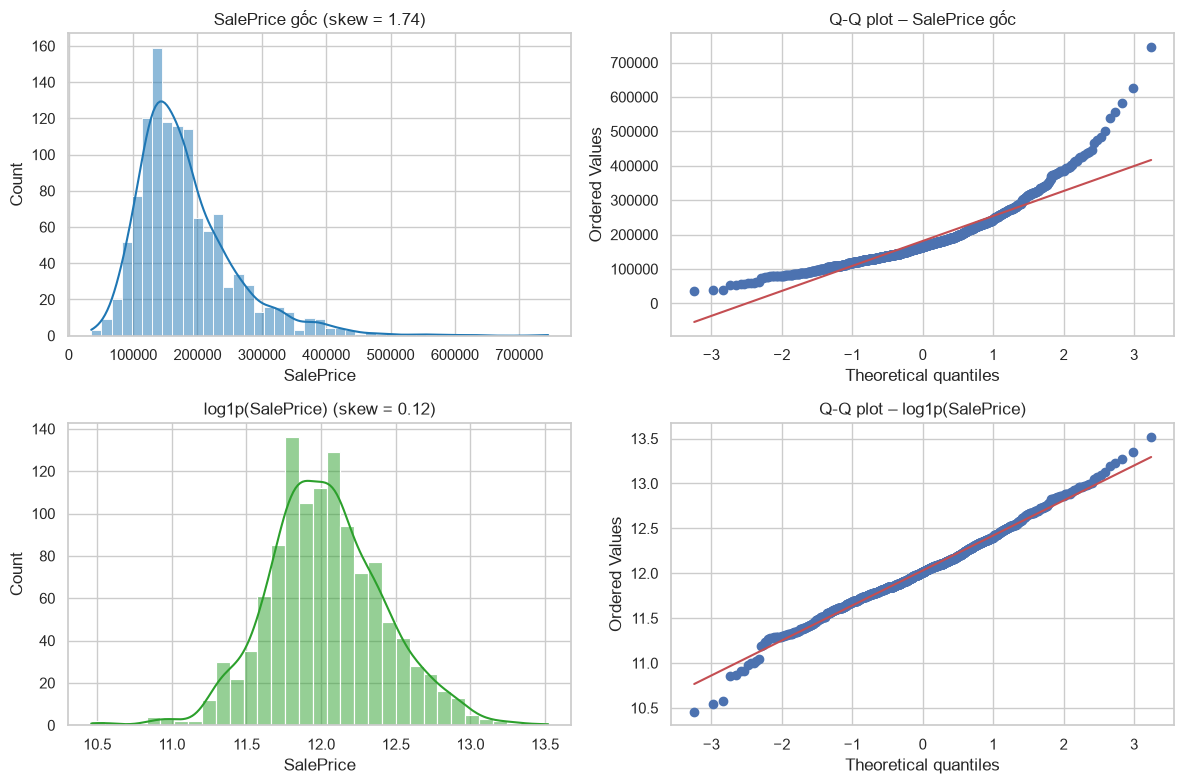

                  skewness  kurtosis
SalePrice            1.743     5.475
log1p(SalePrice)     0.125     0.700


In [8]:
y_log = np.log1p(y_train)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Hàng 1: giá gốc
sns.histplot(y_train, kde=True, ax=axes[0, 0], color="tab:blue")
axes[0, 0].set_title(f"SalePrice gốc (skew = {y_train.skew():.2f})")
stats.probplot(y_train, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q plot – SalePrice gốc")

# Hàng 2: sau log1p
sns.histplot(y_log, kde=True, ax=axes[1, 0], color="tab:green")
axes[1, 0].set_title(f"log1p(SalePrice) (skew = {y_log.skew():.2f})")
stats.probplot(y_log, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot – log1p(SalePrice)")

fig.tight_layout()
save_fig(fig, "eda_01_saleprice_phan_phoi")
plt.show()

print(pd.DataFrame({
    "skewness": [y_train.skew(), y_log.skew()],
    "kurtosis": [y_train.kurt(), y_log.kurt()],
}, index=["SalePrice", "log1p(SalePrice)"]).round(3))

**Nhận xét:**
- Giá nhà trên tập train dao động **34.900 – 745.000 USD**, trung vị **165.000 USD**, trung bình 181.442 USD
  (trung bình > trung vị → phân phối **lệch phải**: có một số căn rất đắt kéo đuôi phải dài).
- Độ lệch **skew = 1,74**, độ nhọn **kurtosis = 5,48**; Q-Q plot cong rõ ở hai đầu → không chuẩn.
- Sau biến đổi **`log1p`**: skew giảm còn **0,13**, kurtosis 0,70; Q-Q plot gần thẳng → gần phân phối chuẩn.

**Quyết định:** huấn luyện mô hình trên `log1p(SalePrice)`, khi dự đoán dùng `expm1` để đổi về USD. Lý do:
1. Mô hình tuyến tính (Ridge/Lasso) giả định phần dư gần chuẩn, phương sai đồng nhất – log giúp thỏa giả định này.
2. Sai số trên thang log tương ứng **sai số tương đối (%)**: sai 20.000 USD với căn 100.000 USD
   nghiêm trọng hơn nhiều so với căn 700.000 USD. RMSE trên log chính là **RMSLE** – chỉ số chính của bài toán.
3. Giảm ảnh hưởng của các căn giá rất cao lên hàm mất mát.

*Ghi chú kỹ thuật:* `log1p` là phép biến đổi cố định (không học tham số từ dữ liệu) nên không gây rò rỉ.
Trong Pipeline có thể dùng `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)`.

## 4. Giá trị khuyết (Missing values)

### 4.1. Tổng quan

In [9]:
so_khuyet = X_train.isna().sum()
bang_khuyet = (
    pd.DataFrame({
        "so_khuyet": so_khuyet,
        "ty_le_%": (so_khuyet / len(X_train) * 100).round(2),
        "kieu": X_train.dtypes.astype(str),
    })
    .query("so_khuyet > 0")
    .sort_values("so_khuyet", ascending=False)
)
print("Số cột có giá trị khuyết:", len(bang_khuyet))
bang_khuyet

Số cột có giá trị khuyết: 19


,so_khuyet,ty_le_%,kieu
PoolQC,1162,99.49,str
MiscFeature,1122,96.06,str
Alley,1094,93.66,str
Fence,935,80.05,str
FireplaceQu,547,46.83,str
LotFrontage,217,18.58,float64
GarageCond,64,5.48,str
GarageType,64,5.48,str
GarageYrBlt,64,5.48,float64
GarageFinish,64,5.48,str


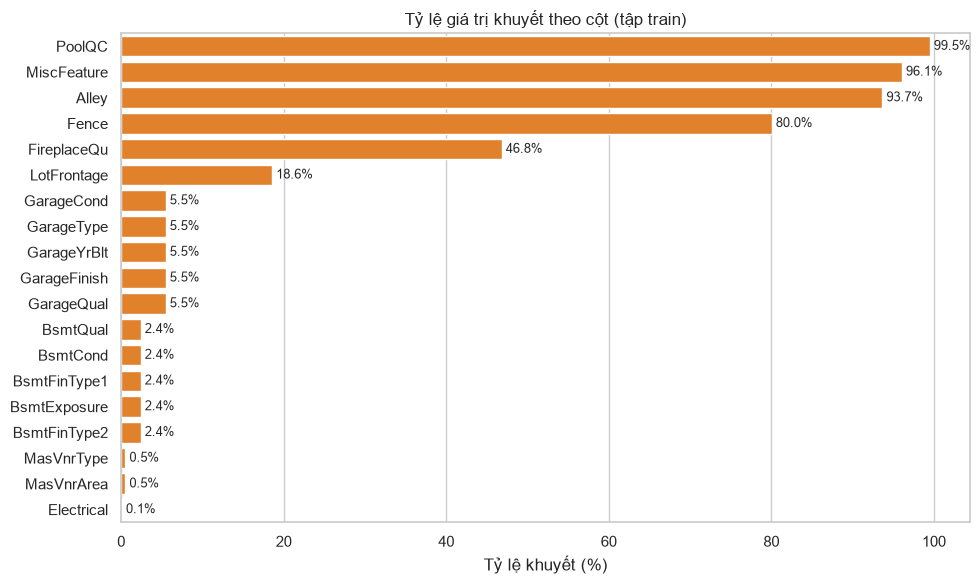

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=bang_khuyet["ty_le_%"], y=bang_khuyet.index, ax=ax, color="tab:orange"
)
ax.set_xlabel("Tỷ lệ khuyết (%)")
ax.set_ylabel("")
ax.set_title("Tỷ lệ giá trị khuyết theo cột (tập train)")
for i, v in enumerate(bang_khuyet["ty_le_%"]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
fig.tight_layout()
save_fig(fig, "eda_02_ty_le_khuyet")
plt.show()

Theo `data_description.txt`, ở nhiều cột **`NA` không có nghĩa là "thiếu thông tin"** mà là
**"căn nhà không có hạng mục đó"** (ví dụ `PoolQC = NA` → *No Pool*). Vì vậy không thể xử lý
mọi NaN giống nhau. Ta kiểm chứng điều này bằng cách đối chiếu với cột số liên quan.

### 4.2. Kiểm chứng: NA có thực sự là "không có"?

In [11]:
def kiem_tra(ten, dk_khuyet, dk_khong_co):
    """So sánh tập dòng bị khuyết với tập dòng 'không có hạng mục'."""
    return {
        "nhom": ten,
        "so_dong_NA": int(dk_khuyet.sum()),
        "so_dong_khong_co": int(dk_khong_co.sum()),
        "so_dong_lech": int((dk_khuyet != dk_khong_co).sum()),
    }


cot_garage = ["GarageType", "GarageYrBlt", "GarageFinish", "GarageQual", "GarageCond"]
cot_bsmt = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
Xt = X_train

kiem_chung = pd.DataFrame([
    kiem_tra("Garage* (5 cột) ~ GarageArea = 0",
             Xt[cot_garage].isna().all(axis=1), Xt["GarageArea"] == 0),
    kiem_tra("Bsmt* (5 cột) ~ TotalBsmtSF = 0",
             Xt[cot_bsmt].isna().all(axis=1), Xt["TotalBsmtSF"] == 0),
    kiem_tra("FireplaceQu ~ Fireplaces = 0",
             Xt["FireplaceQu"].isna(), Xt["Fireplaces"] == 0),
    kiem_tra("PoolQC ~ PoolArea = 0",
             Xt["PoolQC"].isna(), Xt["PoolArea"] == 0),
    kiem_tra("MiscFeature ~ MiscVal = 0",
             Xt["MiscFeature"].isna(), Xt["MiscVal"] == 0),
    kiem_tra("MasVnrType ~ MasVnrArea khuyết",
             Xt["MasVnrType"].isna(), Xt["MasVnrArea"].isna()),
])
kiem_chung

,nhom,so_dong_NA,so_dong_khong_co,so_dong_lech
0,Garage* (5 cột) ~ GarageArea = 0,64,64,0
1,Bsmt* (5 cột) ~ TotalBsmtSF = 0,28,28,0
2,FireplaceQu ~ Fireplaces = 0,547,547,0
3,PoolQC ~ PoolArea = 0,1162,1162,0
4,MiscFeature ~ MiscVal = 0,1122,1124,2
5,MasVnrType ~ MasVnrArea khuyết,6,6,0


In [12]:
# Soi kỹ các trường hợp lệch
print("MiscFeature có giá trị nhưng MiscVal = 0:")
print(Xt.loc[Xt["MiscFeature"].notna() & (Xt["MiscVal"] == 0),
             ["MiscFeature", "MiscVal"]])

print("\nMasVnrType = 'None' nhưng MasVnrArea > 0:")
print(Xt.loc[(Xt["MasVnrType"] == "None") & (Xt["MasVnrArea"] > 0),
             ["MasVnrType", "MasVnrArea"]])

print("\nMasVnrType có loại ốp nhưng MasVnrArea = 0:")
print(Xt.loc[Xt["MasVnrType"].notna() & (Xt["MasVnrType"] != "None")
             & (Xt["MasVnrArea"] == 0), ["MasVnrType", "MasVnrArea"]])

MiscFeature có giá trị nhưng MiscVal = 0:
     MiscFeature  MiscVal
873         Othr        0
1200        Shed        0

MasVnrType = 'None' nhưng MasVnrArea > 0:
     MasVnrType  MasVnrArea
624        None       288.0
773        None         1.0
1230       None         1.0
1300       None       344.0
1334       None       312.0

MasVnrType có loại ốp nhưng MasVnrArea = 0:
     MasVnrType  MasVnrArea
688     BrkFace         0.0
1241      Stone         0.0


**Nhận xét:**
- **Garage, Bsmt, FireplaceQu, PoolQC:** tập dòng NA **trùng khớp 100%** với tập căn *không có*
  hạng mục tương ứng (diện tích / số lượng = 0). → NA ở đây là **thông tin "không có"**, không phải khuyết.
- **MiscFeature:** chỉ lệch 2 dòng (có ghi tiện ích nhưng `MiscVal = 0` – tiện ích không có giá trị quy đổi), hợp lý.
- **MasVnrType:** 6 dòng khuyết trùng với 6 dòng khuyết `MasVnrArea` → khuyết thật nhưng *cùng một hồ sơ*.
  Có một vài dòng mâu thuẫn nhẹ (`"None"` nhưng diện tích > 0 và ngược lại) – lỗi nhập liệu nhỏ, số lượng không đáng kể.

### 4.3. Missing có liên quan đến giá không?
Nếu việc "không có hạng mục" ảnh hưởng đến giá thì đó là **thông tin hữu ích** – không được xóa dòng/cột một cách tùy tiện.

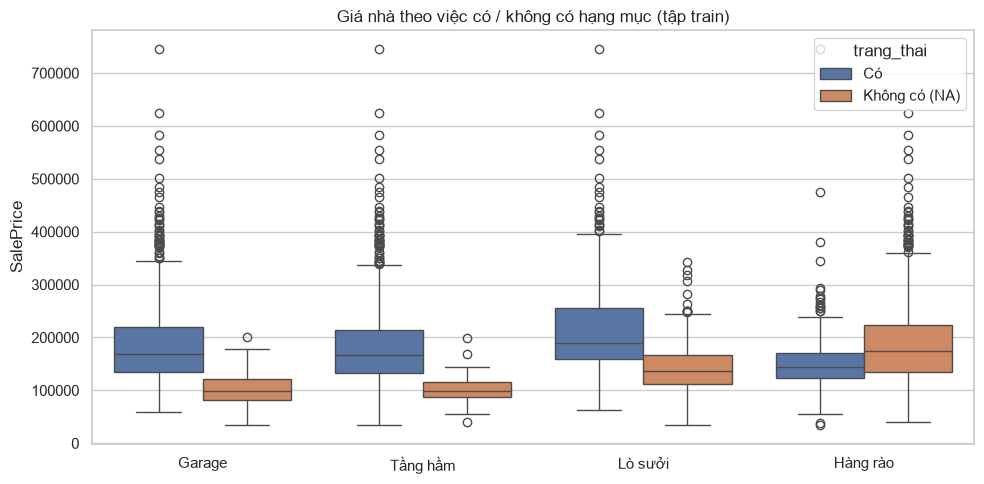

trang_thai,Có,Không có (NA)
hang_muc,,
Garage,169250.0,98950.0
Hàng rào,144000.0,174000.0
Lò sưởi,190000.0,136500.0
Tầng hầm,167000.0,99150.0


In [13]:
nhom_so_sanh = {
    "Garage": Xt["GarageType"].isna(),
    "Tầng hầm": Xt["BsmtQual"].isna(),
    "Lò sưởi": Xt["FireplaceQu"].isna(),
    "Hàng rào": Xt["Fence"].isna(),
}
du_lieu_ve = pd.concat([
    pd.DataFrame({
        "hang_muc": ten,
        "trang_thai": np.where(dk, "Không có (NA)", "Có"),
        "SalePrice": y_train.values,
    })
    for ten, dk in nhom_so_sanh.items()
])

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=du_lieu_ve, x="hang_muc", y="SalePrice", hue="trang_thai", ax=ax)
ax.set_title("Giá nhà theo việc có / không có hạng mục (tập train)")
ax.set_xlabel("")
fig.tight_layout()
save_fig(fig, "eda_03_khuyet_va_gia")
plt.show()

du_lieu_ve.groupby(["hang_muc", "trang_thai"])["SalePrice"].median().unstack()

**Nhận xét:** nhà **không có garage** có giá trung vị chỉ ≈ **99.000 USD**, so với ≈ **169.000 USD** của nhà có garage;
xu hướng tương tự với tầng hầm và lò sưởi. → Trạng thái "không có" **mang thông tin về giá**,
nên giữ lại dưới dạng một hạng mục riêng (`"None"`) thay vì xóa dòng.
Riêng hàng rào thì ngược lại: nhà *có* hàng rào có trung vị **thấp hơn** (≈ 144.000 so với 174.000 USD) –
có thể do hàng rào phổ biến ở các khu nhà cũ; đây là tương quan, không phải nhân quả.

### 4.4. Khuyết thật: `LotFrontage` (chiều dài mặt tiền tiếp giáp đường)

LotFrontage khuyết: 217 (18.6%)
Tương quan với LotArea: 0.427
Tương quan với sqrt(LotArea): 0.605


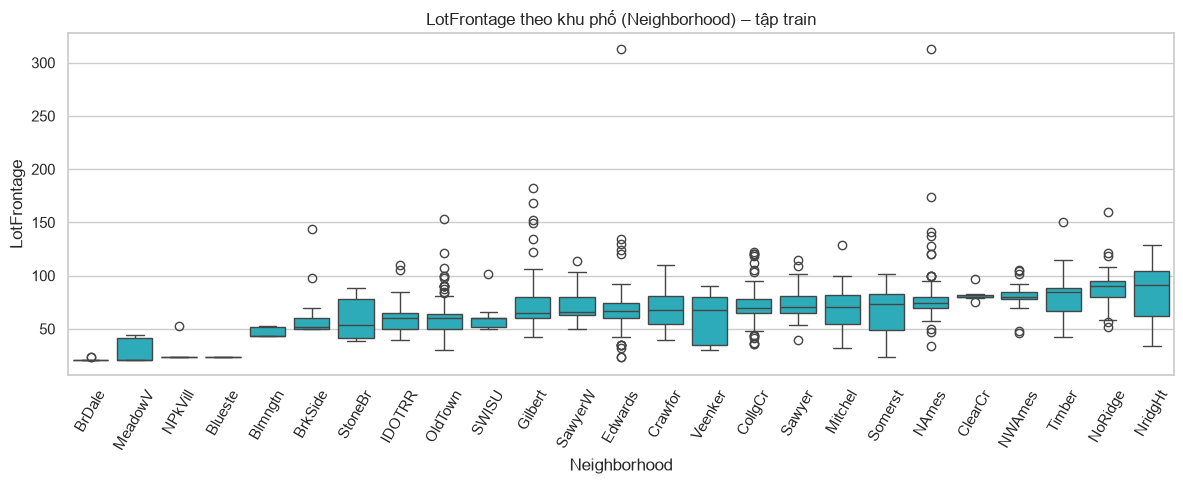

In [14]:
print("LotFrontage khuyết:", Xt["LotFrontage"].isna().sum(),
      f"({Xt['LotFrontage'].isna().mean() * 100:.1f}%)")
print("Tương quan với LotArea:", round(Xt["LotFrontage"].corr(Xt["LotArea"]), 3))
print("Tương quan với sqrt(LotArea):",
      round(Xt["LotFrontage"].corr(np.sqrt(Xt["LotArea"])), 3))

# Trung vị LotFrontage theo khu phố
thu_tu = Xt.groupby("Neighborhood")["LotFrontage"].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=Xt, x="Neighborhood", y="LotFrontage", order=thu_tu, ax=ax,
            color="tab:cyan")
ax.tick_params(axis="x", rotation=60)
ax.set_title("LotFrontage theo khu phố (Neighborhood) – tập train")
fig.tight_layout()
save_fig(fig, "eda_04_lotfrontage_neighborhood")
plt.show()

**Nhận xét:** `LotFrontage` khuyết **18,6%** – đây là **khuyết thật** (mọi lô đất đều tiếp giáp đường).
- Trung vị theo khu phố dao động rất rộng (≈ 21 → 92 feet): các khu nhà liền kề / nhà phố
  (`BrDale`, `MeadowV`, `NPkVill`) mặt tiền hẹp chỉ 21–24 feet, khu nhà cao cấp (`NoRidge`, `NridgHt`)
  rộng ≈ 90 feet → điền một trung vị chung cho cả thành phố sẽ sai lệch lớn.
- Một số khu phố có rất ít dữ liệu (`Blueste` chỉ 1 giá trị, `NPkVill` 5 giá trị) → cần phương án dự phòng.
- Tương quan với $\sqrt{\text{LotArea}}$ (0,61) cao hơn với `LotArea` (0,43) – hợp lý vì mặt tiền là *chiều dài*, diện tích là *bình phương chiều dài*.

**Đề xuất:** điền bằng **trung vị theo `Neighborhood`** (tính trên fold train), dự phòng trung vị toàn cục nếu khu phố không có dữ liệu.
Đây là phép *học từ dữ liệu* nên **bắt buộc phải nằm trong Pipeline** (custom transformer trong `src/`),
không được `fillna` trước khi chia K-Fold.

### 4.5. Chiến lược xử lý giá trị khuyết

In [15]:
chien_luoc = pd.DataFrame([
    ("PoolQC, MiscFeature, Alley, Fence, FireplaceQu",
     "NA = không có", "Điền hằng số 'None'", "Pipeline (SimpleImputer constant)"),
    ("GarageType, GarageFinish, GarageQual, GarageCond",
     "NA = không có garage", "Điền 'None'", "Pipeline"),
    ("BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2",
     "NA = không có tầng hầm", "Điền 'None'", "Pipeline"),
    ("GarageYrBlt", "NA = không có garage (cột số)",
     "Điền YearBuilt của căn đó (không điền 0: năm 0 thành ngoại lai cực lớn) – chốt với Hinh",
     "Pipeline"),
    ("MasVnrType", "Khuyết thật (6 dòng)",
     "Điền 'None' (cùng hồ sơ thiếu MasVnrArea)", "Pipeline"),
    ("MasVnrArea", "Khuyết thật (6 dòng)", "Điền 0", "Pipeline"),
    ("LotFrontage", "Khuyết thật (18,6%)",
     "Trung vị theo Neighborhood", "Pipeline (custom transformer)"),
    ("Electrical", "Khuyết thật (1 dòng)", "Mode ('SBrkr')",
     "Pipeline (SimpleImputer most_frequent)"),
    ("Các cột khác", "Có thể khuyết ở dữ liệu mới",
     "Số: median · Phân loại: most_frequent", "Pipeline – để predict.py an toàn"),
], columns=["Cột", "Bản chất NA", "Cách xử lý đề xuất", "Thực hiện ở đâu"])
chien_luoc

,Cột,Bản chất NA,Cách xử lý đề xuất,Thực hiện ở đâu
0,"PoolQC, MiscFeature, Alley, Fence, FireplaceQu",NA = không có,Điền hằng số 'None',Pipeline (SimpleImputer constant)
1,"GarageType, GarageFinish, GarageQual, GarageCond",NA = không có garage,Điền 'None',Pipeline
2,"BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1...",NA = không có tầng hầm,Điền 'None',Pipeline
3,GarageYrBlt,NA = không có garage (cột số),Điền YearBuilt của căn đó (không điền 0: năm 0...,Pipeline
4,MasVnrType,Khuyết thật (6 dòng),Điền 'None' (cùng hồ sơ thiếu MasVnrArea),Pipeline
5,MasVnrArea,Khuyết thật (6 dòng),Điền 0,Pipeline
6,LotFrontage,"Khuyết thật (18,6%)",Trung vị theo Neighborhood,Pipeline (custom transformer)
7,Electrical,Khuyết thật (1 dòng),Mode ('SBrkr'),Pipeline (SimpleImputer most_frequent)
8,Các cột khác,Có thể khuyết ở dữ liệu mới,Số: median · Phân loại: most_frequent,Pipeline – để predict.py an toàn


**Kết luận Mục 4:**
1. Có **19 cột** khuyết trên tập train, nhưng phần lớn (**14 cột**) là NA mang nghĩa *"không có"*:
   12 cột đã đối chiếu khớp với cột diện tích/số lượng = 0 (Garage, Bsmt, FireplaceQu, PoolQC, MiscFeature),
   `Alley` và `Fence` theo định nghĩa trong `data_description.txt`. Chỉ **4 cột** khuyết thật
   (`LotFrontage`, `MasVnrType`, `MasVnrArea`, `Electrical`), cộng `GarageYrBlt` là trường hợp đặc biệt.
2. **Không xóa cột nào chỉ vì tỷ lệ khuyết cao** (kể cả `PoolQC` 99,5%): NA là thông tin.
   Việc có giữ các cột gần như hằng số hay không sẽ quyết định ở bước chọn đặc trưng.
3. **Không xóa dòng** – tập train chỉ có 1.168 dòng, xóa dòng sẽ mất dữ liệu.
4. Mọi phép điền đều đặt **trong Pipeline** để chống rò rỉ dữ liệu và để `predict.py` xử lý được dữ liệu mới có ô trống.

## 5. Ngoại lai (outliers)

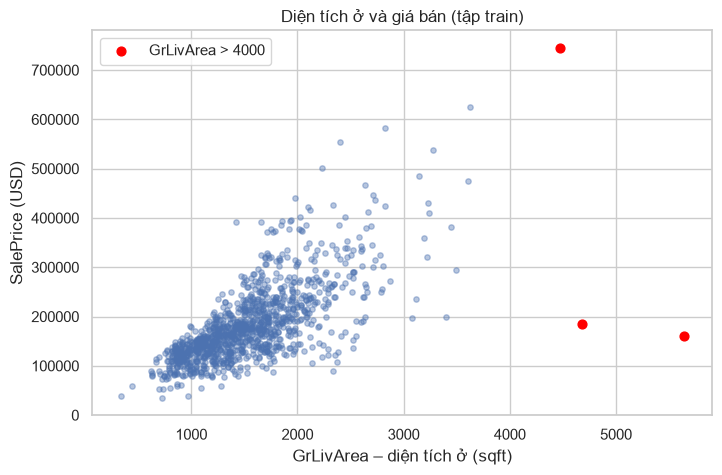

In [16]:
lon = X_train["GrLivArea"] > 4000

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train["GrLivArea"], y_train, alpha=0.4, s=15)
ax.scatter(X_train.loc[lon, "GrLivArea"], y_train[lon], color="red", s=40,
           label="GrLivArea > 4000")
ax.set_xlabel("GrLivArea – diện tích ở (sqft)")
ax.set_ylabel("SalePrice (USD)")
ax.set_title("Diện tích ở và giá bán (tập train)")
ax.legend()
save_fig(fig, "eda_05_ngoai_lai_grlivarea")
plt.show()

In [17]:
cot_xem = ["GrLivArea", "TotalBsmtSF", "OverallQual", "Neighborhood", "SaleCondition"]
X_train.loc[lon, cot_xem].assign(SalePrice=y_train[lon])

,GrLivArea,TotalBsmtSF,OverallQual,Neighborhood,SaleCondition,SalePrice
523,4676,3138,10,Edwards,Partial,184750
1182,4476,2396,10,NoRidge,Abnorml,745000
1298,5642,6110,10,Edwards,Partial,160000


**Nhận xét:**
- `GrLivArea` và giá có quan hệ gần tuyến tính, nhưng có 2 căn rất rộng (4.676 và 5.642 sqft, chất lượng 10/10)
  lại bán chỉ 160–185 nghìn USD, nằm hẳn dưới xu hướng chung.
- Cả 2 đều ở khu `Edwards` và có `SaleCondition = Partial` (nhà chưa hoàn thiện khi bán),
  nên giá không phản ánh giá trị thị trường thật.
- Căn còn lại (4.476 sqft, `NoRidge`, 745 nghìn USD, `SaleCondition = Abnorml`) có giá tương xứng diện tích.
  Tuy nhiên cả tập train chỉ có 3 căn trên 4.000 sqft, quá ít để mô hình học được phân khúc này.
- → Bỏ **tất cả** nhà có `GrLivArea > 4000` theo khuyến nghị của tác giả bộ dữ liệu (De Cock, 2011),
  bằng hàm `remove_outliers` trong `src/data.py`. Ngưỡng theo diện tích đơn giản, dễ giải thích và không dựa vào giá.

So sánh với cách loại ngoại lai máy móc bằng IQR trên `SalePrice`:

In [18]:
q1, q3 = y_train.quantile([0.25, 0.75])
nguong_tren = q3 + 1.5 * (q3 - q1)
print(f"Ngưỡng IQR trên: {nguong_tren:,.0f} USD -> sẽ loại {(y_train > nguong_tren).sum()} căn")

Ngưỡng IQR trên: 342,312 USD -> sẽ loại 48 căn


→ Dùng IQR trên giá sẽ bỏ 48 căn đắt nhưng hoàn toàn hợp lý, làm mô hình mất khả năng dự đoán phân khúc cao cấp.
Vì vậy chỉ loại theo diện tích như trên.

In [19]:
X_train_sach, y_train_sach = remove_outliers(X_train, y_train)
print("Trước:", X_train.shape, "| Sau:", X_train_sach.shape)

Trước: (1168, 79) | Sau: (1165, 79)


**Kết luận Mục 5:**
1. Loại **3 căn** có `GrLivArea > 4000` (2 căn bán khi chưa hoàn thiện, giá thấp bất thường) → train còn **1.165 căn**.
2. Chỉ loại trên **tập train**, trước khi đưa vào Pipeline. Tập test giữ nguyên để đánh giá khách quan.
   Bước này nằm ngoài Pipeline vì transformer của scikit-learn không được xóa dòng; ngưỡng cố định,
   không học từ tập test nên không gây rò rỉ.
3. Các giá trị lớn khác (ví dụ `LotArea` tới 215.245 sqft) là nhà thật, không loại;
   độ lệch của các biến diện tích sẽ xử lý bằng biến đổi log (Mục 6–8).

*Phần tiếp theo (23–24/11): Mục 6 Tương quan · Mục 7 Biến phân loại · Mục 8 Tổng kết chiến lược tiền xử lý.*